In [9]:
from typing import Annotated

from langchain.chat_models import init_chat_model
from typing_extensions import TypedDict
from langgraph.graph.message import add_messages
from langchain_groq import ChatGroq
from langchain_core.tools import tool

In [3]:
from dotenv import load_dotenv
load_dotenv()

True

In [5]:
class State(TypedDict):
    messages: Annotated[list,add_messages]

In [15]:
@tool
def get_stock_price(symbol:str)->float:
    """Get the stock price for a given stock symbol."""
    return{
       "MSFT": 200.3,
        "AAPL": 100.4,
        "AMZN": 150.0,
        "RIL":87.6
    }.get(symbol,0.0)

tools = [get_stock_price]

llm = ChatGroq(model="openai/gpt-oss-120b")

llm_with_tools=llm.bind_tools(tools)

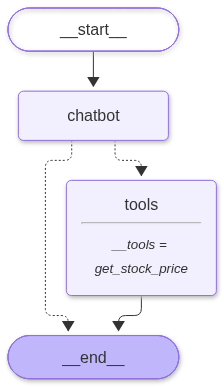

In [17]:
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.graph import StateGraph, START, END


def chatbot(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}
builder  = StateGraph(State)

builder.add_node(chatbot)
builder.add_node("tools",ToolNode(tools))

builder.add_edge(START,"chatbot")
builder.add_conditional_edges("chatbot",tools_condition)
builder.add_edge("chatbot",END)
graph = builder.compile()

from IPython.display import display,Image
display(Image(graph.get_graph().draw_mermaid_png()))



In [21]:
state = graph.invoke({"messages":[{"role":"user","content":"What is the price of AMZN stock right now?"}]})
print(state["messages"][-1].content)

150.0


In [22]:
msg = "I want to buy 20 AMZN stocks using current price. then 15 MSFT . what will ve the total cost?"
state = graph.invoke({"messages":[{"role":"user","content":msg}]})
print(state["messages"][-1].content)

150.0
